# 2026 Annual report

In [2]:
%load_ext autoreload
%autoreload 2

In [11]:
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pytz
import seaborn as sns

from usagestats import visual
from usagestats.bookingdb import BookingDB

folder = Path(
    "/run/user/1000/gvfs/smb-share:server=istore,share=microscopy_group_share,user=jeromeb/Admin/Usage Stats/2026"
)
export = folder / "report"
export.mkdir(parents=True,exist_ok=True)
db_file = folder / "bookings2.db"
local_tz = pytz.timezone("Europe/London")
start_date = datetime.fromisoformat("2025-11-01").replace(tzinfo=local_tz)
num_weeks = 52
end_date = start_date + timedelta(weeks=num_weeks)  # iso-format data yyyy-mm-dd
drop_bookings_type = ["service", "maintenance", "training"]
drop_instrument = ["Analysis PC1", "Analysis PC2", "Analysis PC3", "Analysis PC4"]

booking_types = ["default", "service", "maintenance", "training"]
divisions = [
    "Unknown",
    "Cell Biology",
    "Neurobiology",
    "PNAC",
    "Structural Studies",
    "University",
]


In [ ]:
groups = pd.read_csv(folder / "groups.csv")
users = pd.read_csv(folder / "users.csv")
training = pd.read_csv(folder / "training.csv")
calendars = pd.read_csv(folder / "calendars.csv")

# get a cookie from the curl command copied from firefox dev tools and save it in a cookie.txt file
with open("cookie.txt", "r") as f:
    curl_str = f.read()

# check that the calendars url are uniques
assert calendars["url"].is_unique, "Calendar URLs are not unique!"

known_users = users
print(
    f"There are {len(calendars)} calendars for {calendars['instrument'].nunique()} instruments."
)
print(f"There are {len(users)} known users.")
print(f"There are {len(groups)} groups.")

# Load all calendars in the database
Path(db_file).unlink(True)
with BookingDB(db_file, curl_str=curl_str) as db:
    db.create_calendars_from_df(calendars)
    db.create_instruments()
    db.create_booking_types(booking_types)
    db.create_division(divisions)
    db.create_groups(groups)
    df, duplicates = db.create_events(known_users)

Use the training record to populate missing people

In [ ]:
# Load all users
with BookingDB(db_file) as db:
    users = db.get_unique_users_in_range(start_date, end_date)

# Get users with no groups
users_no_group = users[users["division"].str.contains("Unknow")][
    ["id", "email", "name"]
].reset_index(drop=True)

# Load and format training csv file
training = pd.read_csv(folder / "training.csv")
training = training[~training["Email"].isna()]
training = training[~training["Group"].isna()]
training["email"] = training["Email"]
training["group"] = training["Group"].apply(lambda x: x.split(" ")[-1])
training["id"] = training["email"].apply(lambda x: x.split("@")[0])
training = training[["id", "group"]].drop_duplicates("id").reset_index(drop=True)

new_users = pd.merge(users_no_group, training, how="inner", on="id")

with BookingDB(db_file) as db:
    db.update_users_group_from_df(new_users)

# Check the remaining unknown users
with BookingDB(db_file) as db:
    unique_users = db.get_unique_users_in_range(start_date, end_date)
unique_users[unique_users["group"] == "Unknown"]  # .to_csv(folder/"new_new_user.csv")

In [ ]:
new_new_users = pd.read_csv(folder / "new_new_user.csv")
with BookingDB(db_file) as db:
    db.update_users_group_from_df(new_new_users)
with BookingDB(db_file) as db:
    unique_users = db.get_unique_users_in_range(start_date, end_date)
print("Unknown users")
unique_users[unique_users["group"] == "Unknown"]

## Report

In [12]:
import matplotlib

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

sns.set_context("paper")
sns.set_style("whitegrid")

In [13]:
with BookingDB(db_file) as db:
    bookings = db.get_events_in_range(start_date, end_date)


# fix booking types
def get_type_from_str(x):
    types = {
        "serv": "service",
        "maint": "maintenance",
        "train": "training",
        "maintenace": "maintenance",
    }
    for y in types:
        if x.lower().find(y) >= 0:
            return types[y]
    return "default"


bookings["type"] = [get_type_from_str(x) for x in bookings["subject"]]

### Booking by type

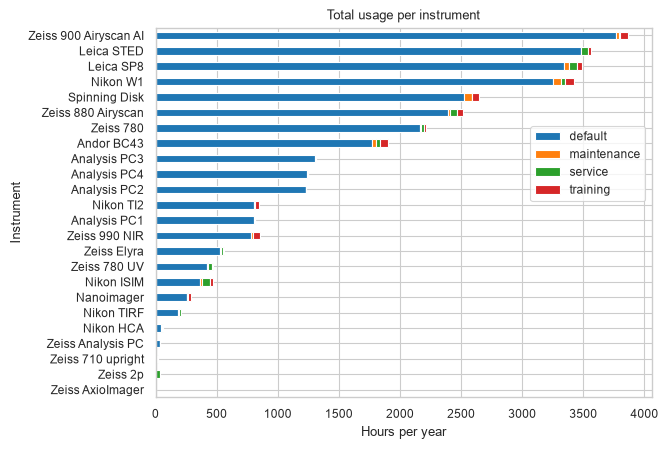

In [14]:
hours_insts = (
    bookings.groupby(["type", "instrument"], as_index=False)
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .pivot(index="instrument", values="hours", columns="type")
    .fillna(0)
    .sort_values("default")
)

hours_insts.plot(kind="barh", stacked=True)
plt.xlabel("Hours per year")
plt.ylabel("Instrument")
plt.legend(bbox_to_anchor=(1, 0.75))
plt.title("Total usage per instrument")
plt.savefig(folder / "per_type.pdf", pad_inches=1.2, bbox_inches="tight")

(
    bookings.groupby(["type", "instrument"], as_index=False)
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .pivot_table(index="instrument", values="hours", columns="type", margins=True)
    .fillna(0)
    .sort_values("default")
    .to_csv(folder / "per_type.csv")
)


### Filtering

In [15]:
# excludes special bookings
bookings_flt = bookings[~bookings["type"].isin(drop_bookings_type)]
# excludes instruments
bookings_flt = bookings_flt[~bookings_flt["instrument"].isin(drop_instrument)]
# exclude unknownbookings = bookings[bookings["group"] != "Unknown"]
bookings_flt = bookings_flt[bookings_flt["division"] != "Unknown"]

In [16]:
info_str = visual.get_title_str(bookings_flt, start_date, end_date)

### Per Division

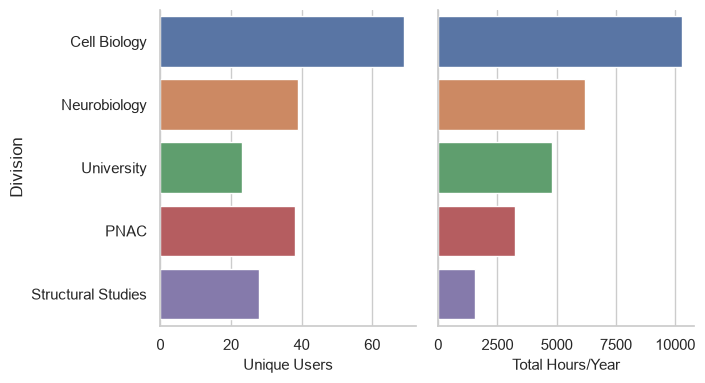

In [22]:
with BookingDB(db_file) as db:
    unique_users = db.get_unique_users_in_range(start_date, end_date)

unique_users = unique_users[unique_users["division"] != "Unknown"]

# df unique_user has columns ['id', 'division']
# df booking_flt has columns ['hours', 'division']

sns.set_theme(style="whitegrid", palette="muted")

user_div = (
    unique_users.groupby("division")[["id"]]
    .count()
    .rename(columns={"id": "Unique Users"})
)

hours_div = (
    bookings_flt.groupby("division")
    .agg(hours=("hours", "sum"))
    .rename(columns={"hours": "Total Hours"})
)

# Merge, sort by primary metric, and melt for Seaborn
per_div = (
    user_div.merge(hours_div, left_index=True, right_index=True)
    .sort_values("Total Hours", ascending=False)
    .reset_index()
    .melt(id_vars=["division"], var_name="Metric", value_name="Value")
)

# 3. Enhanced catplot
g = sns.catplot(
    data=per_div,
    kind="bar",
    x="Value",
    y="division",
    hue="division",  # Differentiate the two panels by metric color
    palette="deep",  # Professional color palette
    col="Metric",
    height=4.5,
    aspect=0.8,
    sharex=False,  # Allows independent scales for users vs. hours
)

# 4. Polish titles and labels
g.set_titles(template="")
g.set_axis_labels("Usage Value", "Division")
g.figure.subplots_adjust(top=0.85)
# g.fig.suptitle(info_str,y=1.05)
x_labels = ["Unique Users", "Total Hours/Year"]
for ax, label in zip(g.axes.flat, x_labels):
    ax.set_xlabel(label, fontsize=11)
plt.savefig(export / "per_division.pdf")
per_div.pivot_table(
    values="Value", index="division", columns="Metric", margins=True
).to_csv(export / "per_division.csv")

### Usage per group

<Figure size 2000x2000 with 0 Axes>

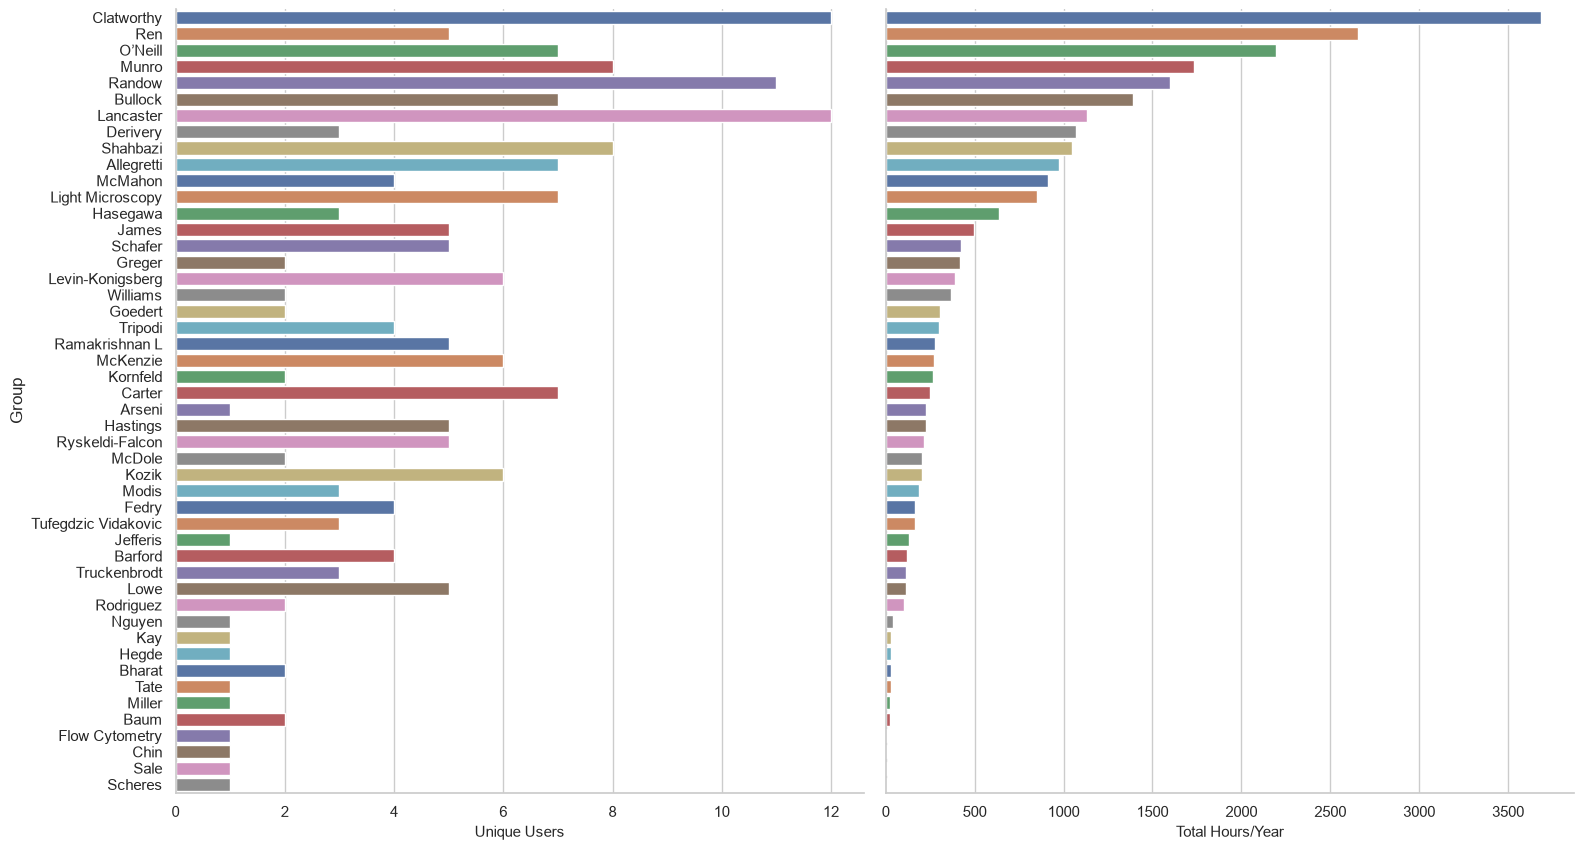

In [23]:
from usagestats import visual

user_grps = (
    unique_users.groupby("group")[["id"]].count().rename(columns={"id": "Unique Users"})
)

hours_grps = (
    bookings_flt.groupby("group")
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .sort_values("hours", ascending=False)
)

# Merge, sort by primary metric, and melt for Seaborn
per_grps = (
    user_grps.merge(hours_grps, left_index=True, right_index=True)
    .sort_values("hours", ascending=False)
    .reset_index()
    .melt(id_vars=["group"], var_name="Metric", value_name="Value")
)

# 3. Enhanced catplot
plt.figure(figsize=(20, 20))
g = sns.catplot(
    data=per_grps,
    kind="bar",
    x="Value",
    y="group",
    hue="group",  # Differentiate the two panels by metric color
    palette="deep",  # Professional color palette
    col="Metric",
    height=10,
    aspect=0.8,
    sharex=False,  # Allows independent scales for users vs. hours
)

# 4. Polish titles and labels
g.set_titles(template="")
g.set_axis_labels("Usage Value", "Group")
g.figure.subplots_adjust(top=0.85)
x_labels = ["Unique Users", "Total Hours/Year"]
for ax, label in zip(g.axes.flat, x_labels):
    ax.set_xlabel(label, fontsize=11)
plt.savefig(export / "per_group.pdf", pad_inches=1.2, bbox_inches="tight")
per_grps.pivot_table(
    values="Value", index="group", columns="Metric", margins=True
).to_csv(export / "per_group.csv")

### Usage per instruments

<Figure size 2000x2000 with 0 Axes>

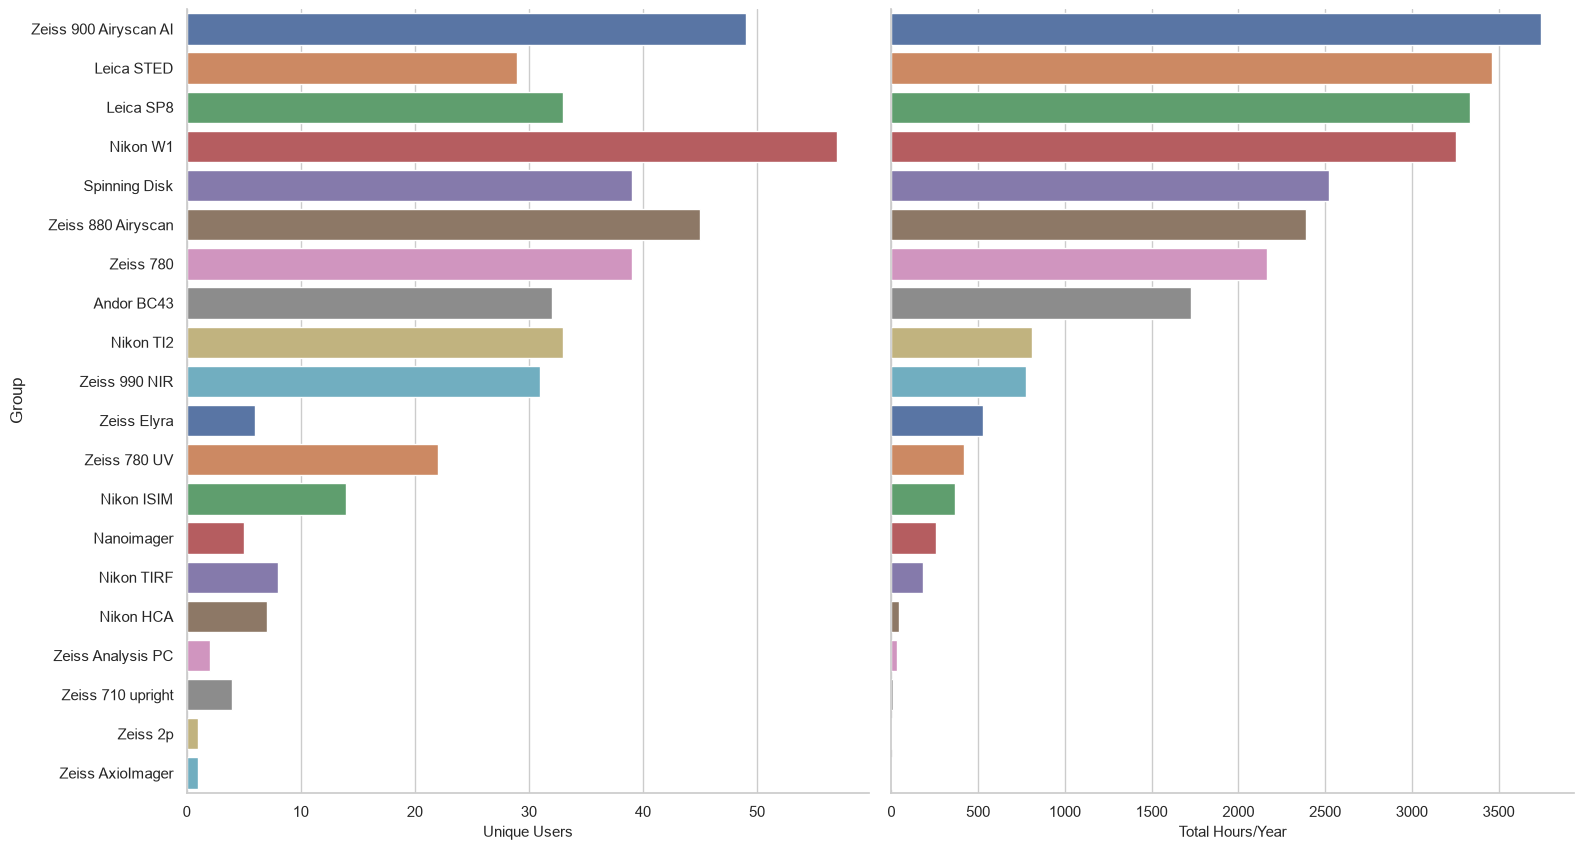

In [24]:
from usagestats import visual

user_inst = (
    bookings_flt.groupby("instrument")["user"]
    .nunique()
    .to_frame()
    .rename(columns={"user": "Unique Users"})
)

hours_inst = (
    bookings_flt.groupby("instrument")["hours"]
    .sum()
    .to_frame()
    .sort_values("hours", ascending=False)
    .rename(columns={"hours": "Total Hours"})
)

# Merge, sort by primary metric, and melt for Seaborn
per_inst = (
    user_inst.merge(hours_inst, left_index=True, right_index=True)
    .sort_values("Total Hours", ascending=False)
    .reset_index()
    .melt(id_vars=["instrument"], var_name="Metric", value_name="Value")
)

# 3. Enhanced catplot
plt.figure(figsize=(20, 20))
g = sns.catplot(
    data=per_inst,
    kind="bar",
    x="Value",
    y="instrument",
    hue="instrument",  # Differentiate the two panels by metric color
    palette="deep",  # Professional color palette
    col="Metric",
    height=10,
    aspect=0.8,
    sharex=False,  # Allows independent scales for users vs. hours
)

# 4. Polish titles and labels
g.set_titles(template="")
g.set_axis_labels("Usage Value", "Group")
g.figure.subplots_adjust(top=0.85)
x_labels = ["Unique Users", "Total Hours/Year"]
for ax, label in zip(g.axes.flat, x_labels):
    ax.set_xlabel(label, fontsize=11)
plt.savefig(export / "per_instrument.pdf", pad_inches=1.2, bbox_inches="tight")
per_inst.pivot_table(
    values="Value", index="instrument", columns="Metric", margins=True
).to_csv(export / "per_instrument.csv")


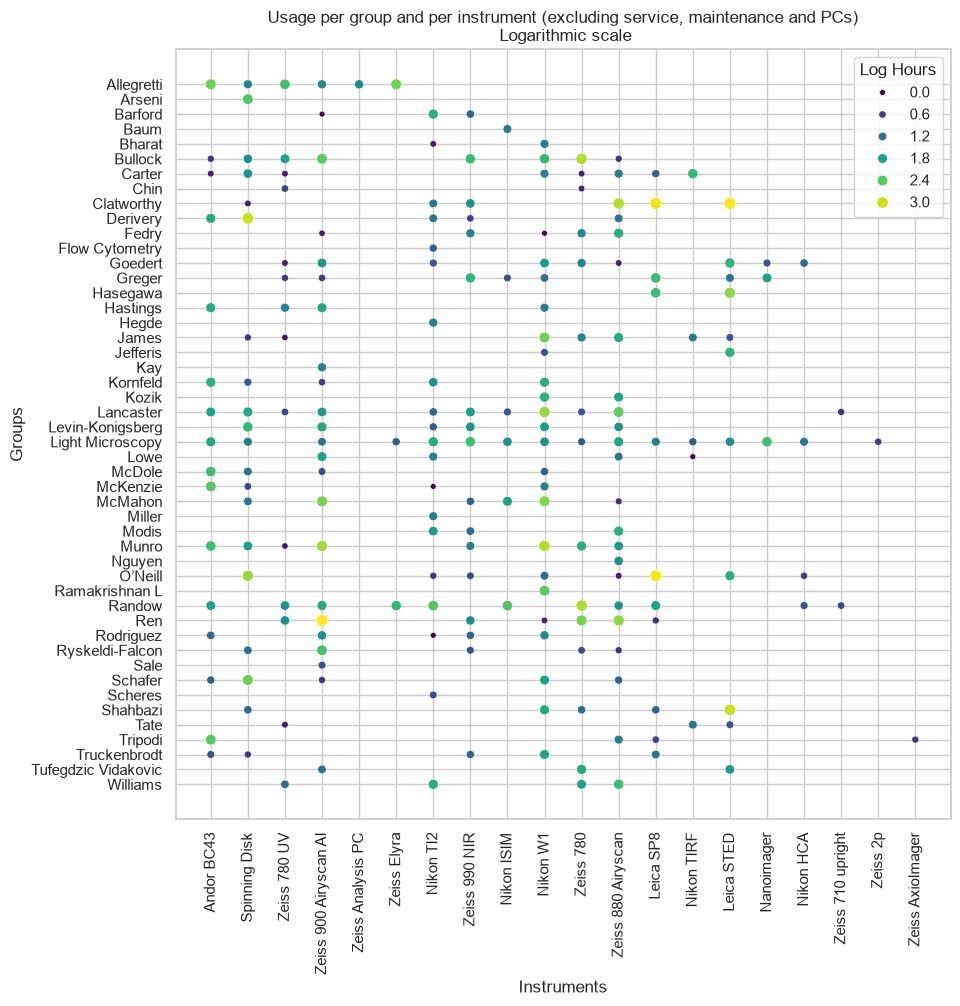

In [25]:
import math

# bookings.groupby(['Group','Instrument'], as_index=False)['Hours'].agg('sum').pivot(index="Group",columns="Instrument",values='Hours').fillna(0).to_csv('usage-per-group-per-instrument.csv')
f, x = plt.subplots(figsize=(10, 10))
tmp = bookings_flt.groupby(["group", "instrument"], as_index=False)["hours"].agg("sum")
tmp["hours"] = [math.log10(x) for x in tmp["hours"]]
cmap = sns.color_palette("viridis", as_cmap=True)
# order = tmp.groupby('Group').agg(time=('Hours',sum)).sort_values('time',ascending=False).index.values
sns.scatterplot(
    data=tmp, x="instrument", y="group", size="hours", hue="hours", palette=cmap
)
plt.xticks(rotation=90)
plt.ylabel("Groups")
plt.xlabel("Instruments")
plt.title(
    "Usage per group and per instrument (excluding service, maintenance and PCs)\n Logarithmic scale"
)
plt.legend(title="Log Hours")
plt.savefig(
    export / "matrix.pdf", pad_inches=1.2, bbox_inches="tight"
)

### By users

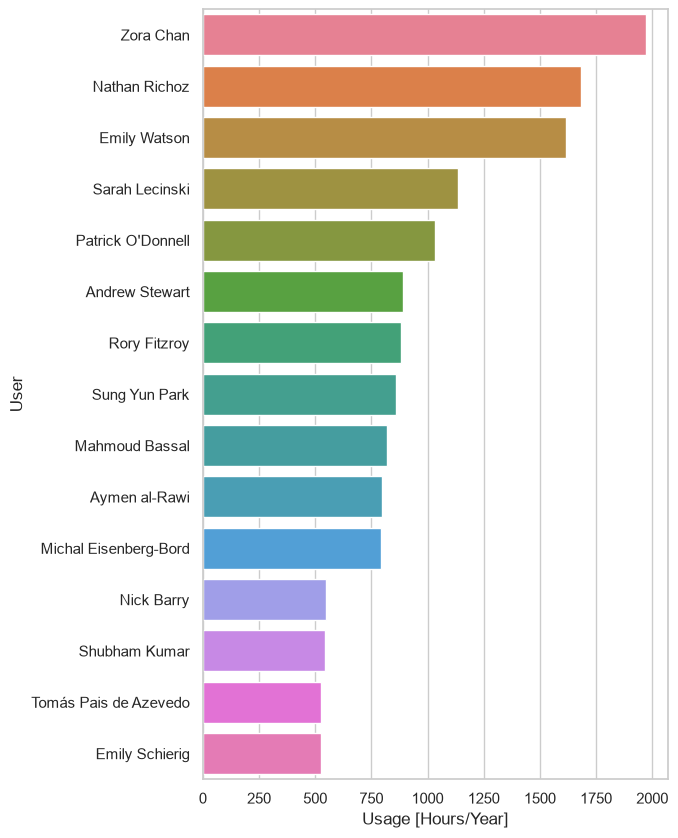

In [26]:
from usagestats import visual

top_users = (
    bookings.groupby("user")["hours"]
    .sum()
    .to_frame()
    .sort_values("hours", ascending=False)
)

f, ax = plt.subplots(figsize=(6, 10))
ax = sns.barplot(data=top_users.iloc[:15], x="hours", y="user", hue="user")
plt.xlabel("Usage [Hours/Year]")
plt.ylabel("User")
# plt.title("Number of hours per user (top 15)" + info_str)
plt.savefig(export / "winners.pdf", pad_inches=1.2, bbox_inches="tight")

### Weekly usage

In [27]:
usage = visual.weekly_usage_by_instrument(bookings_flt, start_date, end_date)

In [ ]:
import numpy as np

# figure for each instruments

col_order = (
    bookings_flt.groupby("instrument")["hours"].sum().sort_values(ascending=False).index
)
# g = sns.FacetGrid(usage, col="Instrument", col_wrap=5, col_order=col_order)
# p = g.map(sns.barplot, "Week", "Usage", order=np.arange(num_weeks))
g = sns.catplot(
    usage,
    kind="bar",
    x="Week",
    y="Usage",
    col="Instrument",
    col_wrap=5,
    col_order=col_order,
    height=2,
)
g.set_titles(template="{col_name}")
averages = usage.groupby("Instrument")["Usage"].agg(["mean"])
avg_global = usage["Usage"].mean()

for k, a in enumerate(g.axes):
    mic = a.get_title()
    avg = averages["mean"][mic]
    a.set_title(f"{mic} ({avg:.0f}h/w)")
    # a.text(15,130,f'average:{avg:.0f}h/w')
    # a.set_subtitle(f'average:{avg:.0f}h/w')
    a.axhline(avg_global, color="r", linestyle="-")
    a.axhline(avg, color="g", linestyle="-")
    a.set_ylabel("Usage [Hours/Week]")
    a.set_xticks(np.arange(0, num_weeks, step=10))
    a.set_xticklabels(np.arange(0, num_weeks, step=10))
    a.set_ylim([0, 24 * 7])
# plt.subplots_adjust(top=0.9)
# plt.suptitle(
#     f"Usage per week and per instrument excluding maintenance, service and training\naverage {avg_global:.0f}h/w"
# )
plt.savefig(export / "per_week.pdf")